# Классификация дохода с помощью дерева решений
Задание 3. По 14 признакам человека предсказываем годовой доход: **не более 50 000 долларов** или **более 50 000 долларов**.

Запустите ячейки сверху вниз в Google Colab. Если файлов `adult.data` и `adult.test` нет рядом с блокнотом, они загрузятся автоматически. Данные: [UCI Adult](https://archive.ics.uci.edu/dataset/2/adult), Barry Becker и Ronny Kohavi, лицензия CC BY 4.0.

Сначала сравним Information gain, Gain ratio и Gini index на всей исходной обучающей выборке. Затем зафиксируем Information gain и проверим доли обучения 60%, 70%, 80% и 90%.

In [1]:
# Блокнот: загрузка Adult, построение деревьев и оценка на отложенных данных.
from pathlib import Path
from urllib.request import urlretrieve
from textwrap import fill

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

COLUMNS = ["age", "workclass", "fnlwgt", "education", "education-num",
           "marital-status", "occupation", "relationship", "race", "sex",
           "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]
CRITERIA = {"information_gain": "Information gain", "gain_ratio": "Gain ratio",
            "gini": "Gini index"}


def load_data(filename):
    # Вход: имя adult.data или adult.test. Выход: таблица признаков и класса 0/1.
    path = Path(filename)
    if not path.exists():
        urlretrieve("https://archive.ics.uci.edu/ml/machine-learning-databases/adult/" + filename, path)
    data = pd.read_csv(path, names=COLUMNS, skipinitialspace=True, comment="|")
    # В adult.test классы заканчиваются точкой; неизвестные категории обозначены ?.
    data = data.replace("?", "Unknown")
    data["income"] = (data["income"].str.rstrip(".") == ">50K").astype(int)
    return data


train_data = load_data("adult.data")
test_data = load_data("adult.test")
data = pd.concat([train_data, test_data], ignore_index=True)
print(f"Обучающая выборка: {len(train_data):,}; тестовая: {len(test_data):,}; всего: {len(data):,}")
print(f"Доля класса >50K: {data['income'].mean():.2%}")
display(train_data.head())

Обучающая выборка: 32,561; тестовая: 16,281; всего: 48,842
Доля класса >50K: 23.93%


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


## Как строится дерево
Рекурсивный алгоритм соответствует схеме **TreeGrowth** из презентации: проверить условие остановки → найти лучшее разбиение → разделить записи → построить дочерние деревья. В листе выбирается самый частый класс.

Числовой признак проверяем условием `признак ≤ порог`, категориальный — `признак = категория`. Перебираем пороги между соседними различными числами и все отдельные категории. Это бинарный вариант дерева.

Для доли положительного класса $p$:
- энтропия: $H(p)=-p\log_2 p-(1-p)\log_2(1-p)$, причём $0\log_2 0=0$;
- **Information gain**: $IG=H(S)-w_L H(S_L)-w_R H(S_R)$;
- **Gain ratio**: $GR=IG/H(w_L)$, где $H(w_L)$ — энтропия размеров двух ветвей;
- **Gini index**: $G(p)=2p(1-p)$. Выбираем максимальное уменьшение $G(S)-w_L G(S_L)-w_R G(S_R)$.

Здесь $w_L$ и $w_R$ — доли записей в левой и правой ветвях. Во всех вариантах максимизируем оценку разбиения. Для Gain ratio используется непосредственно отношение IG к энтропии ветвления, без дополнительных эвристик C4.5.

Чтобы полностью показать деревья, во всех экспериментах ограничиваем глубину тремя разбиениями от корня и оставляем не менее 30 записей в каждом листе. Все обучающие записи участвуют в расчёте. Остановка также происходит в чистом узле или при отсутствии разбиения с положительной оценкой.

In [2]:
def impurity(p, criterion):
    # Вход: доля класса 1 (число или массив), критерий. Выход: мера неоднородности.
    p = np.asarray(p, dtype=float)
    if criterion == "gini":
        return 2 * p * (1 - p)
    # Ограничение аргумента log предотвращает log(0), сохраняя нулевой вклад.
    return -(p * np.log2(np.maximum(p, 1e-15))
             + (1 - p) * np.log2(np.maximum(1 - p, 1e-15)))


def build_tree(X, y, criterion, max_depth=3, min_leaf=30, depth=0):
    # Вход: признаки X, классы y, критерий, ограничения роста и текущая глубина.
    # Выход: словарь узла с классом, числом записей и, при наличии, двумя потомками.
    n = len(y)
    positive = int(y.sum())
    node = {"class": int(positive > n - positive), "n": n}
    if depth >= max_depth or positive in (0, n) or n < 2 * min_leaf:
        return node

    parent_impurity = impurity(positive / n, criterion)
    best_score, best_split = 1e-12, None
    for feature in X.columns:
        values = X[feature].to_numpy()
        numeric = pd.api.types.is_numeric_dtype(X[feature])
        if numeric:
            order = np.argsort(values)
            sorted_values, sorted_y = values[order], y[order]
            # Каждый кандидат отделяет все значения слева от следующего отличного.
            positions = np.flatnonzero(sorted_values[:-1] != sorted_values[1:])
            candidates = (sorted_values[positions].astype(float)
                          + sorted_values[positions + 1].astype(float)) / 2
            left_n = positions + 1
            left_positive = np.cumsum(sorted_y)[positions]
        else:
            candidates, inverse = np.unique(values, return_inverse=True)
            left_n = np.bincount(inverse)
            left_positive = np.bincount(inverse, weights=y)

        valid = (left_n >= min_leaf) & (n - left_n >= min_leaf)
        if not valid.any():
            continue
        candidates, left_n, left_positive = candidates[valid], left_n[valid], left_positive[valid]
        weight = left_n / n
        gain = (parent_impurity
                - weight * impurity(left_positive / left_n, criterion)
                - (1 - weight) * impurity((positive - left_positive) / (n - left_n), criterion))
        scores = gain / impurity(weight, "information_gain") if criterion == "gain_ratio" else gain
        best = int(np.argmax(scores))
        if scores[best] > best_score:
            best_score = scores[best]
            best_split = feature, candidates[best], numeric

    if best_split is not None:
        feature, value, numeric = best_split
        left = (X[feature] <= value if numeric else X[feature] == value).to_numpy()
        node.update(feature=feature, value=value, numeric=numeric)
        node["left"] = build_tree(X.loc[left], y[left], criterion, max_depth, min_leaf, depth + 1)
        node["right"] = build_tree(X.loc[~left], y[~left], criterion, max_depth, min_leaf, depth + 1)
    return node


def predict(tree, X):
    # Вход: обученное дерево и таблица признаков. Выход: массив предсказаний 0/1.
    predictions = []
    for row in X.to_dict("records"):
        node = tree
        while "feature" in node:
            value = row[node["feature"]]
            go_left = value <= node["value"] if node["numeric"] else value == node["value"]
            node = node["left"] if go_left else node["right"]
        predictions.append(node["class"])
    return np.array(predictions)


def classify(data, criterion="information_gain", train_fraction=1.0,
             test_data=None, max_depth=3, min_leaf=30):
    # Вход: таблица с income=0/1, критерий, доля обучения, внешняя тестовая таблица
    # (только для доли 1.0), максимальная глубина и минимальный размер листа.
    # Выход: дерево и словарь размеров выборок и метрик; без теста метрик нет.
    if criterion not in CRITERIA or not 0 < train_fraction <= 1:
        raise ValueError("Проверьте критерий и долю обучения: 0 < доля <= 1.")
    if max_depth < 0 or min_leaf < 1:
        raise ValueError("Глубина должна быть >= 0, размер листа >= 1.")
    if train_fraction == 1:
        train, test = data, test_data
    else:
        if test_data is not None:
            raise ValueError("При доле < 1 тестовая выборка выделяется из data.")
        train, test = train_test_split(data, train_size=train_fraction,
                                       stratify=data["income"], random_state=42)
    tree = build_tree(train.drop(columns="income"), train["income"].to_numpy(),
                      criterion, max_depth, min_leaf)
    result = {"Обучение": len(train), "Тест": 0 if test is None else len(test)}
    if test is not None:
        actual = test["income"].to_numpy()
        predicted = predict(tree, test.drop(columns="income"))
        result.update(accuracy=accuracy_score(actual, predicted),
                      precision=precision_score(actual, predicted, zero_division=0),
                      recall=recall_score(actual, predicted, zero_division=0),
                      f1=f1_score(actual, predicted, zero_division=0))
    return tree, result

## Визуализация дерева
На рисунке показано **всё построенное дерево**. Внутренний узел содержит условие; `n` — число обучающих записей в узле. Ветка «да» идёт влево, «нет» — вправо. В листе указан предсказываемый класс. Цвет листа: синий — `≤50K`, оранжевый — `>50K`.

In [3]:
def plot_tree(tree, title, filename=None):
    # Вход: дерево, заголовок, необязательное имя PNG. Выход: рисунок на экране/в файле.
    fig, ax = plt.subplots(figsize=(10, 4.6))
    positions = {}
    leaf_x = 0

    def place(node, depth=0):
        # Возвращает горизонтальную координату узла; листья располагаются по порядку.
        nonlocal leaf_x
        if "feature" not in node:
            x = leaf_x
            leaf_x += 1
        else:
            x = (place(node["left"], depth + 1) + place(node["right"], depth + 1)) / 2
        positions[id(node)] = (x, -depth)
        return x

    def draw(node):
        # Рисует узел и рекурсивно его потомков в заранее рассчитанных координатах.
        x, y = positions[id(node)]
        if "feature" in node:
            value = f"{node['value']:g}" if node["numeric"] else str(node["value"])
            condition = f"{node['feature']} {'≤' if node['numeric'] else '='} {value}"
            label = fill(condition, width=23, break_long_words=False, break_on_hyphens=False)
            color = "#f1f3f5"
            for side, answer in [("left", "да"), ("right", "нет")]:
                child = node[side]
                cx, cy = positions[id(child)]
                ax.plot([x, cx], [y, cy], color="#77838c", linewidth=1, zorder=1)
                ax.text((x + cx) / 2, (y + cy) / 2, answer, fontsize=9,
                        ha="center", va="center", backgroundcolor="white", zorder=2)
                draw(child)
        else:
            label = ">50K" if node["class"] else "≤50K"
            color = "#ffe0b2" if node["class"] else "#d8eaf7"
        ax.text(x, y, f"{label}\nn={node['n']}", ha="center", va="center", fontsize=10,
                bbox=dict(boxstyle="round,pad=0.35", facecolor=color, edgecolor="#73808a"), zorder=3)

    place(tree)
    draw(tree)
    ax.set_xlim(-0.65, max(leaf_x - 0.35, 0.65))
    ax.set_ylim(min(y for x, y in positions.values()) - 0.5, 0.65)
    ax.set_title(title, fontsize=13, pad=10)
    ax.axis("off")
    fig.tight_layout()
    if filename:
        fig.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()

## Эксперимент 1 — три критерия
Каждое дерево обучаем на **100% записей `adult.data`**. Качество проверяем на отдельной исходной выборке `adult.test`. Значение `train_fraction=1.0` означает использование всех переданных обучающих данных, а не оценку модели на них же.

Положительный класс для precision, recall и F1 — **доход >50K**. Accuracy — доля всех правильных ответов; precision — доля верных среди ответов «>50K»; recall — доля найденных людей с доходом >50K; F1 — гармоническое среднее precision и recall. Все метрики находятся в диапазоне от 0 до 1.

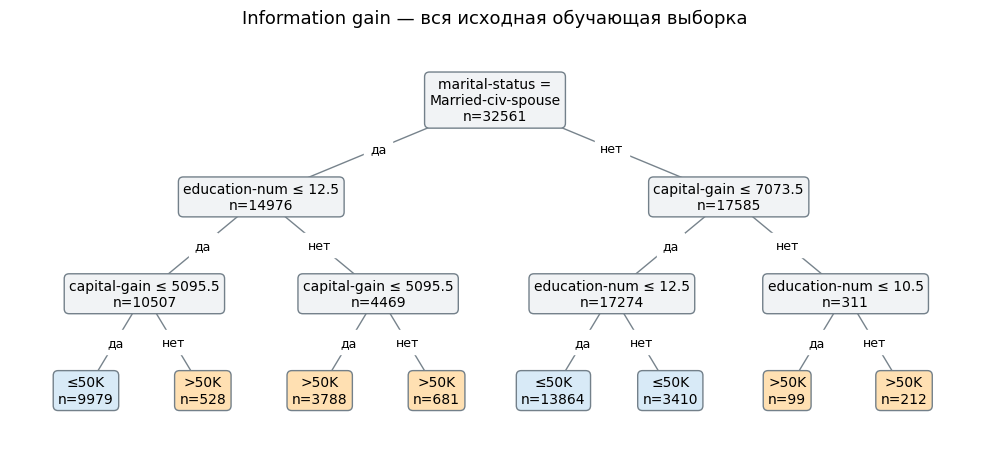

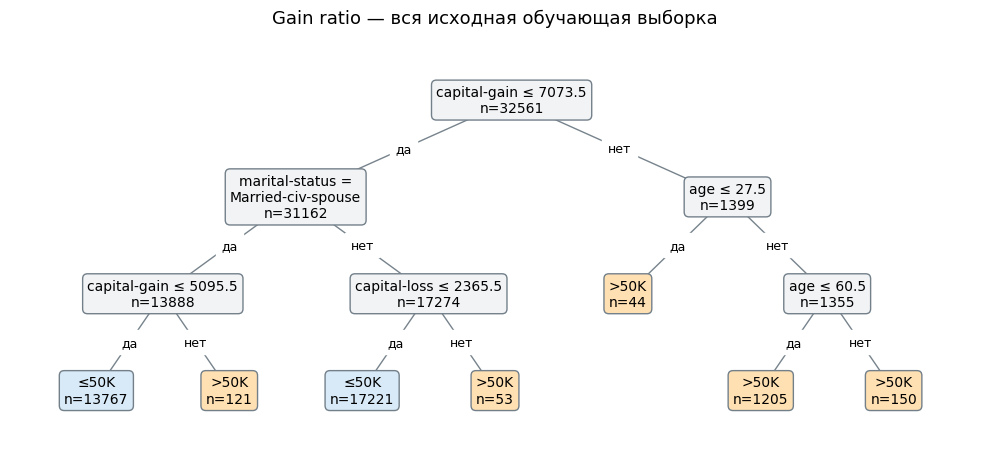

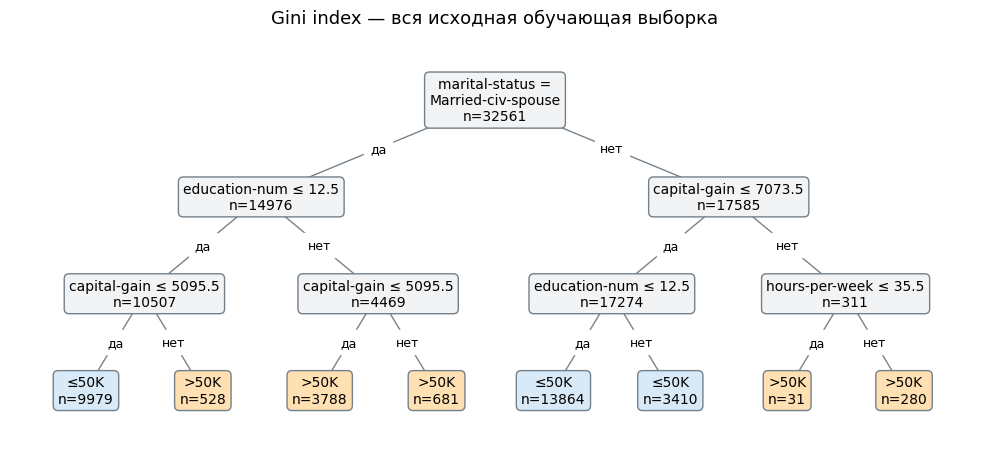

,Критерий,Обучение,Тест,accuracy,precision,recall,f1
0,Information gain,32561,16281,0.8448,0.7553,0.5073,0.6069
1,Gain ratio,32561,16281,0.8080,0.9813,0.1908,0.3195
2,Gini index,32561,16281,0.8448,0.7553,0.5073,0.6069


In [4]:
# Основные параметры; их можно менять для собственных экспериментов.
MAX_DEPTH = 3
MIN_LEAF = 30
METRICS = ["accuracy", "precision", "recall", "f1"]
Path("figures").mkdir(exist_ok=True)

criterion_results = []
criterion_trees = {}
for criterion, label in CRITERIA.items():
    tree, result = classify(train_data, criterion=criterion, train_fraction=1.0,
                            test_data=test_data, max_depth=MAX_DEPTH, min_leaf=MIN_LEAF)
    criterion_trees[criterion] = tree
    criterion_results.append({"Критерий": label, **result})
    plot_tree(tree, f"{label} — вся исходная обучающая выборка",
              f"figures/tree_{criterion}.png")

criterion_results = pd.DataFrame(criterion_results)
display(criterion_results.round(4))

## Эксперимент 2 — доля обучающей выборки
Объединяем обе исходные выборки (48 842 записи) и заново делим их на обучение и тест. Внутри каждого запуска строки обучающей и тестовой частей не пересекаются. Стратификация сохраняет доли классов, `random_state=42` делает разделение воспроизводимым. Строки с неизвестными категориями сохраняются как `Unknown`.

Фиксируем **Information gain**, глубину и минимальный размер листа. Меняем только долю обучения: 60%, 70%, 80% и 90%. Это отдельный эксперимент: его тестовые части отличаются от исходного `adult.test` и между запусками. Результаты одного разбиения не доказывают превосходство какого-либо соотношения.

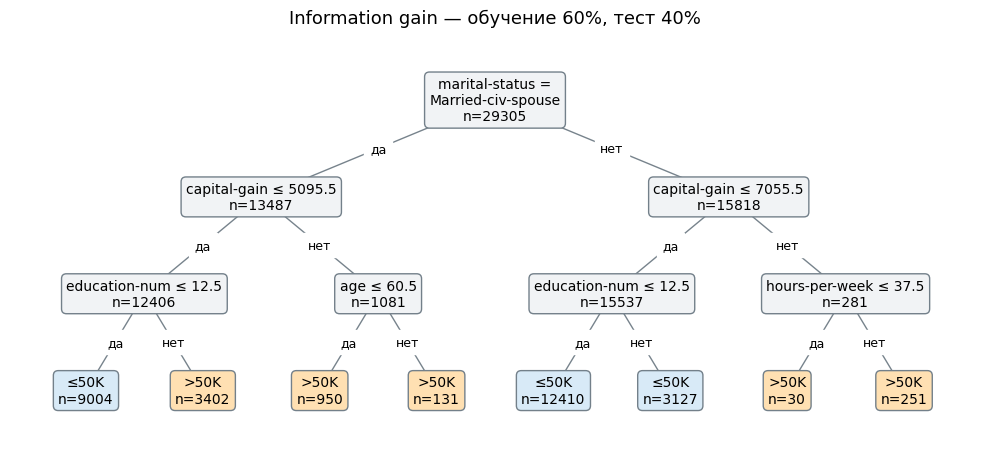

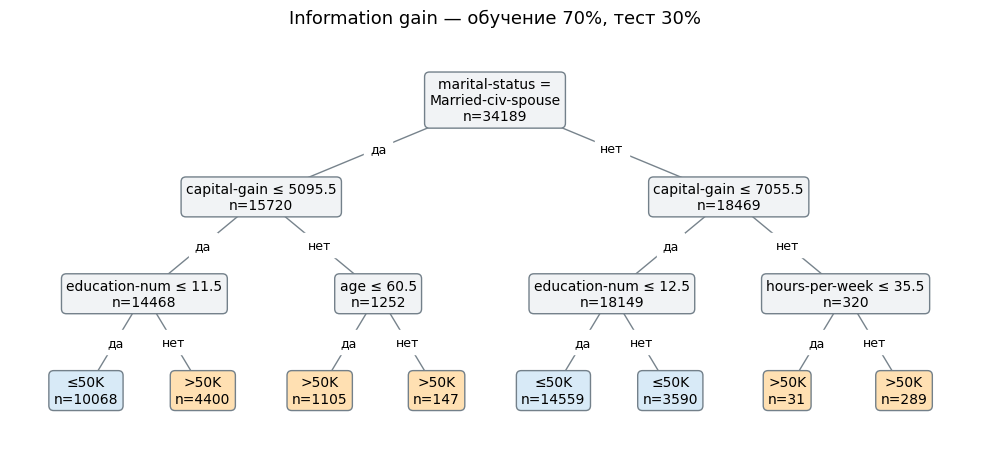

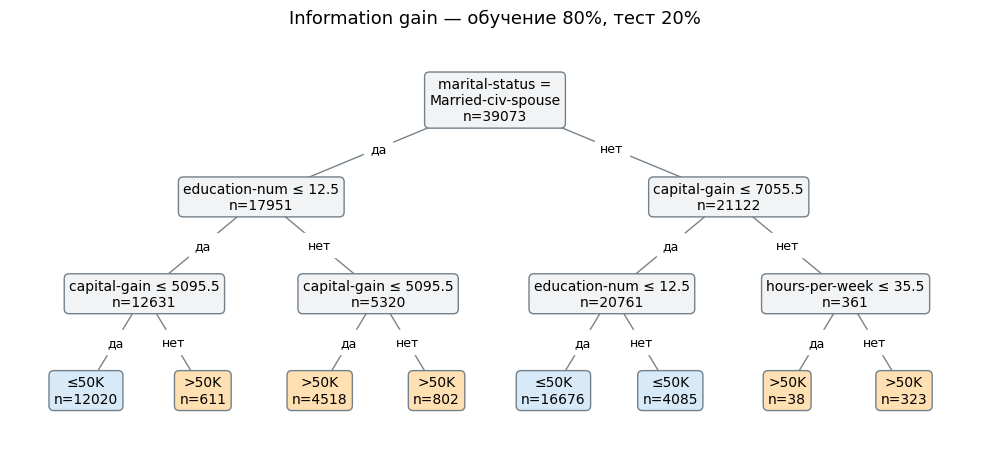

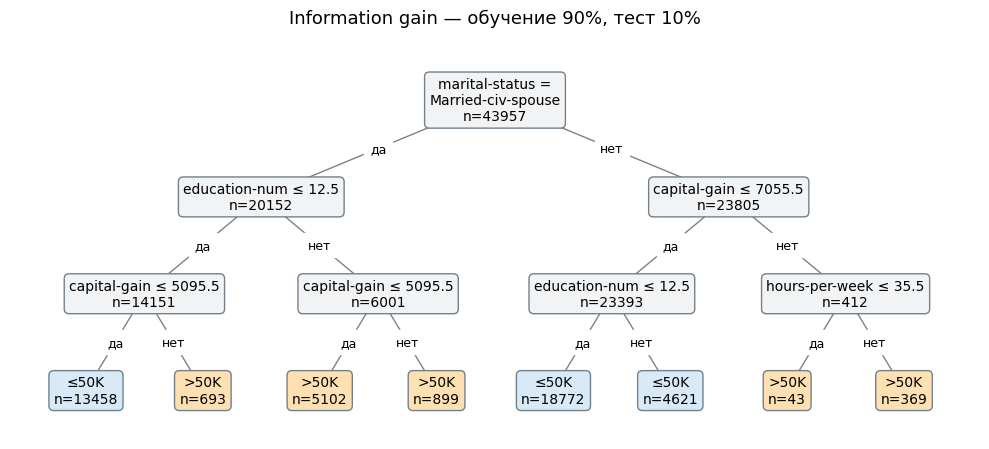

,"Обучение, %",Обучение,Тест,accuracy,precision,recall,f1
0,60,29305,19537,0.8462,0.7672,0.5132,0.6150
1,70,34189,14653,0.8438,0.7374,0.5391,0.6228
2,80,39073,9769,0.8455,0.7592,0.5192,0.6167
3,90,43957,4885,0.8448,0.7618,0.5115,0.6121


In [5]:
FIXED_CRITERION = "information_gain"
TRAIN_FRACTIONS = [0.6, 0.7, 0.8, 0.9]

fraction_results = []
fraction_trees = {}
for fraction in TRAIN_FRACTIONS:
    tree, result = classify(data, criterion=FIXED_CRITERION, train_fraction=fraction,
                            max_depth=MAX_DEPTH, min_leaf=MIN_LEAF)
    percent = round(fraction * 100)
    fraction_trees[percent] = tree
    fraction_results.append({"Обучение, %": percent, **result})
    plot_tree(tree, f"{CRITERIA[FIXED_CRITERION]} — обучение {percent}%, тест {100 - percent}%",
              f"figures/tree_train_{percent}.png")

fraction_results = pd.DataFrame(fraction_results)
display(fraction_results.round(4))

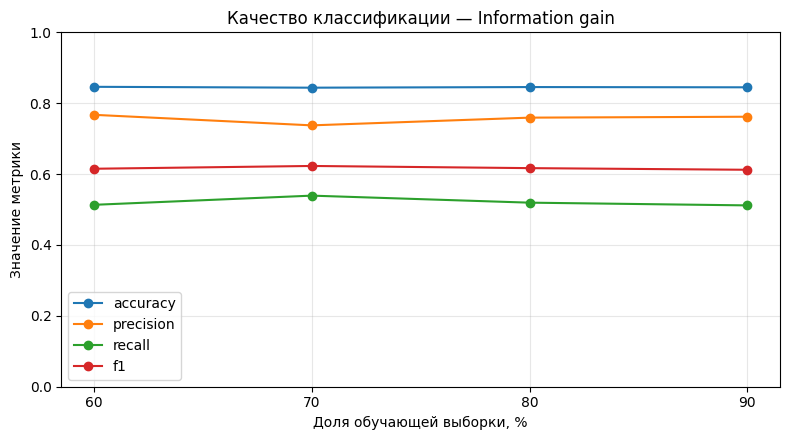

In [6]:
# Показываем все четыре метрики при каждом соотношении обучения и теста.
fig, ax = plt.subplots(figsize=(8, 4.5))
for metric in METRICS:
    ax.plot(fraction_results["Обучение, %"], fraction_results[metric], marker="o", label=metric)
ax.set(xlabel="Доля обучающей выборки, %", ylabel="Значение метрики",
       title=f"Качество классификации — {CRITERIA[FIXED_CRITERION]}",
       xticks=[60, 70, 80, 90], ylim=(0, 1))
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("figures/metrics.png", dpi=200, bbox_inches="tight")
plt.show()

## Как понимать результаты
Сравнивайте не только accuracy, но и recall: класс `>50K` встречается реже, поэтому правильное определение большинства ещё не означает хорошего распознавания высокого дохода. F1 учитывает и precision, и recall.

Увеличение обучающей выборки не обязано улучшать каждую метрику при каждом шаге. На результат влияют состав теста, выбранные пороги и ограничение глубины. Похожая форма деревьев при разных разбиениях указывает на устойчивость выбранных условий в этих запусках, но не на причинную связь между признаками и доходом.